# Blinkit Grocery Sales Analysis
## 01 – Data Understanding
### One command / operation per Jupyter code cell

**Objective:** Understand the raw dataset before making any changes.

**Input:** `Dataset/BlinkIT-Grocery-Data.csv`

**Notebook rule:** Each command or small operation is placed in its own code cell. Run cells from top to bottom and inspect each output.

> This notebook only inspects the raw data. It does not clean, modify, or overwrite the CSV.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
pd.set_option('display.max_columns', None)       #Set Pandas to display all columns.
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')   #Set a readable floating-point display format.
sns.set_theme(style='whitegrid')     # Set the chart theme.

## 2. Locate and load the raw dataset

Set the expected CSV path

In [3]:
DATA_PATH = Path('../Dataset/BlinkIT-Grocery-Data.csv')
DATA_PATH.exists()
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Update DATA_PATH to the location of BlinkIT-Grocery-Data.csv."
    )

df = pd.read_csv(DATA_PATH)

In [4]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100,15.100,145.479,5.000
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.009,11.800,115.349,5.000
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.026,13.850,165.021,5.000
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042,12.150,126.505,5.000
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.034,19.600,55.161,5.000


## 3. Dataset dimensions and columns

Check the number of rows and columns.

In [ ]:
df.shape

(8523, 12)

Display column names as a Python list.

In [14]:
df.columns.tolist()

['Item Fat Content',
 'Item Identifier',
 'Item Type',
 'Outlet Establishment Year',
 'Outlet Identifier',
 'Outlet Location Type',
 'Outlet Size',
 'Outlet Type',
 'Item Visibility',
 'Item Weight',
 'Sales',
 'Rating']

## 4. Data types and structure

Display concise DataFrame information: column names, non-null counts, data types, and memory usage.

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


Display each column's data type.

In [16]:
df.dtypes

Item Fat Content                 str
Item Identifier                  str
Item Type                        str
Outlet Establishment Year      int64
Outlet Identifier                str
Outlet Location Type             str
Outlet Size                      str
Outlet Type                      str
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

Count columns by data type.

In [17]:
df.dtypes.value_counts()

str        7
float64    4
int64      1
Name: count, dtype: int64

## 5. Statistical summaries

Generate descriptive statistics for numerical columns.

In [18]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,"8,523.000","8,523.000","7,060.000","8,523.000","8,523.000"
mean,"2,016.451",0.066,12.858,140.993,3.966
std,3.189,0.052,4.643,62.275,0.606
min,"2,011.000",0.000,4.555,31.290,1.000
25%,"2,014.000",0.027,8.774,93.826,4.000
50%,"2,016.000",0.054,12.600,143.013,4.000
75%,"2,018.000",0.095,16.850,185.644,4.200
max,"2,022.000",0.328,21.350,266.888,5.000


Generate descriptive statistics for categorical columns.

In [20]:
print(df.describe(include='object').T)

                     count unique                    top  freq
Item Fat Content      8523      5                Low Fat  5089
Item Identifier       8523   1559                  FDW13    10
Item Type             8523     16  Fruits and Vegetables  1232
Outlet Identifier     8523     10                 OUT027   935
Outlet Location Type  8523      3                 Tier 3  3350
Outlet Size           8523      3                 Medium  3631
Outlet Type           8523      4      Supermarket Type1  5577


C:\Users\Sripada Pavankumar\AppData\Local\Temp\ipykernel_23196\3793693820.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include='object').T)


Generate a summary for all columns.

In [21]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item Fat Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Establishment Year,"8,523.000",NaN,NaN,NaN,"2,016.451",3.189,"2,011.000","2,014.000","2,016.000","2,018.000","2,022.000"
Outlet Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Location Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Size,8523,3,Medium,3631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Type,8523,4,Supermarket Type1,5577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Visibility,"8,523.000",NaN,NaN,NaN,0.066,0.052,0.000,0.027,0.054,0.095,0.328
Item Weight,"7,060.000",NaN,NaN,NaN,12.858,4.643,4.555,8.774,12.600,16.850,21.350


## 6. Missing-value inspection

Count missing values in each column.

In [22]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

Calculate missing-value percentages.

In [23]:
(df.isnull().sum() / len(df) * 100).round(2)

Item Fat Content             0.000
Item Identifier              0.000
Item Type                    0.000
Outlet Establishment Year    0.000
Outlet Identifier            0.000
Outlet Location Type         0.000
Outlet Size                  0.000
Outlet Type                  0.000
Item Visibility              0.000
Item Weight                 17.170
Sales                        0.000
Rating                       0.000
dtype: float64

Create a combined missing-value summary table.

In [24]:
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('Missing Values', ascending=False)

missing_summary

,Missing Values,Missing Percentage
Item Weight,1463,17.170
Item Fat Content,0,0.000
Item Type,0,0.000
Item Identifier,0,0.000
Outlet Establishment Year,0,0.000
Outlet Identifier,0,0.000
Outlet Size,0,0.000
Outlet Location Type,0,0.000
Outlet Type,0,0.000
Item Visibility,0,0.000


Identify columns that contain at least one missing value.

In [25]:
missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Missing Percentage
Item Weight,1463,17.170


Plot missing-value counts for columns that contain missing values.

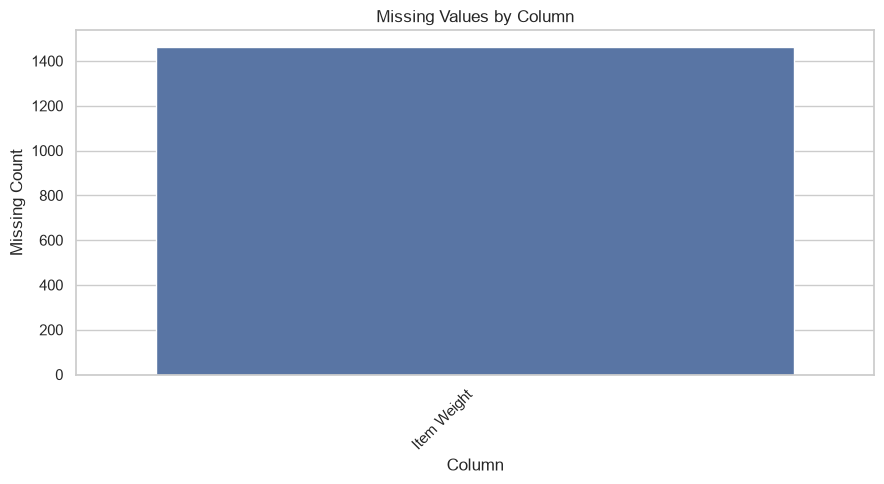

In [26]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

if missing_counts.empty:
    print('No missing values found.')
else:
    plt.figure(figsize=(9, 5))
    sns.barplot(x=missing_counts.index, y=missing_counts.values)
    plt.title('Missing Values by Column')
    plt.xlabel('Column')
    plt.ylabel('Missing Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

## 7. Duplicate inspection

Count exact duplicate rows.

In [27]:
df.duplicated().sum()

np.int64(0)

Display exact duplicate rows, if any.

In [28]:
df[df.duplicated(keep=False)].head(20)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating


## 8. Categorical-column inspection

Identify categorical columns.

In [29]:
categorical_columns = df.select_dtypes(include=['object', 'category']).columns

C:\Users\Sripada Pavankumar\AppData\Local\Temp\ipykernel_23196\3445425799.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object', 'category']).columns


Display the categorical column names.

In [30]:
categorical_columns.tolist()

['Item Fat Content',
 'Item Identifier',
 'Item Type',
 'Outlet Identifier',
 'Outlet Location Type',
 'Outlet Size',
 'Outlet Type']

Count unique non-null values in each categorical column.

In [31]:
df[categorical_columns].nunique()

Item Fat Content           5
Item Identifier         1559
Item Type                 16
Outlet Identifier         10
Outlet Location Type       3
Outlet Size                3
Outlet Type                4
dtype: int64

Inspect unique values in Item Fat Content.

In [32]:
df['Item Fat Content'].value_counts(dropna=False)

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Inspect unique values in Item Type.

In [33]:
df['Item Type'].value_counts(dropna=False)

Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

Inspect unique values in Outlet Size.

In [34]:
df['Outlet Size'].value_counts(dropna=False)

Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64

Inspect unique values in Outlet Location Type.

In [35]:
df['Outlet Location Type'].value_counts(dropna=False)

Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

Inspect unique values in Outlet Type.

In [36]:
df['Outlet Type'].value_counts(dropna=False)

Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

Display unique values for every categorical column. This may produce a longer output.

In [37]:
for column in categorical_columns:
    print(f'\\n{column}')
    print(df[column].dropna().unique())

\nItem Fat Content
<StringArray>
['Regular', 'Low Fat', 'low fat', 'LF', 'reg']
Length: 5, dtype: str
\nItem Identifier
<StringArray>
['FDX32', 'NCB42', 'FDR28', 'FDL50', 'DRI25', 'FDS52', 'NCU05', 'NCD30',
 'FDW20', 'FDX25',
 ...
 'DRO59', 'NCW05', 'NCI55', 'FDQ33', 'FDB46', 'FDQ60', 'FDF38', 'FDU60',
 'NCX53', 'FDE52']
Length: 1559, dtype: str
\nItem Type
<StringArray>
['Fruits and Vegetables',    'Health and Hygiene',          'Frozen Foods',
                'Canned',           'Soft Drinks',             'Household',
           'Snack Foods',                  'Meat',                'Breads',
           'Hard Drinks',                'Others',                 'Dairy',
             'Breakfast',          'Baking Goods',               'Seafood',
         'Starchy Foods']
Length: 16, dtype: str
\nOutlet Identifier
<StringArray>
['OUT049', 'OUT018', 'OUT046', 'OUT013', 'OUT045', 'OUT017', 'OUT010',
 'OUT027', 'OUT035', 'OUT019']
Length: 10, dtype: str
\nOutlet Location Type
<StringArray>
[

## 9. Numerical-column inspection

Identify numerical columns.

In [38]:
numerical_columns = df.select_dtypes(include=np.number).columns

Display numerical column names.

In [39]:
numerical_columns.tolist()

['Outlet Establishment Year',
 'Item Visibility',
 'Item Weight',
 'Sales',
 'Rating']

Count unique values in numerical columns.

In [40]:
df[numerical_columns].nunique()

Outlet Establishment Year       9
Item Visibility              7880
Item Weight                   415
Sales                        5938
Rating                         39
dtype: int64

Display the numerical summary, transposed for readability.

In [41]:
df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Outlet Establishment Year,"8,523.000","2,016.451",3.189,"2,011.000","2,014.000","2,016.000","2,018.000","2,022.000"
Item Visibility,"8,523.000",0.066,0.052,0.000,0.027,0.054,0.095,0.328
Item Weight,"7,060.000",12.858,4.643,4.555,8.774,12.600,16.850,21.350
Sales,"8,523.000",140.993,62.275,31.290,93.826,143.013,185.644,266.888
Rating,"8,523.000",3.966,0.606,1.000,4.000,4.000,4.200,5.000


## 10. Basic data-quality checks

Check whether Item Visibility contains zero values.

In [47]:
(df['Item Visibility'] == 0).sum()

np.int64(526)

Check for negative Item Visibility values.

In [43]:
(df['Item Visibility'] < 0).sum()

np.int64(0)

Check for negative Item Weight values, ignoring missing values.

In [48]:
(df['Item Weight'] < 0).sum()

np.int64(0)

Check for negative Sales values.

In [49]:
(df['Sales'] < 0).sum()

np.int64(0)

Check whether Rating values fall outside the expected 0 to 5 range.

In [46]:
(~df['Rating'].between(0, 5)).sum()

np.int64(0)

## 11. Initial dataset profile

Create a compact profile of the raw dataset.

In [50]:
dataset_profile = pd.DataFrame({
    'Metric': [
        'Total Records',
        'Total Columns',
        'Numerical Columns',
        'Categorical Columns',
        'Total Missing Cells',
        'Columns with Missing Values',
        'Exact Duplicate Rows'
    ],
    'Value': [
        len(df),
        df.shape[1],
        len(numerical_columns),
        len(categorical_columns),
        int(df.isnull().sum().sum()),
        int((df.isnull().sum() > 0).sum()),
        int(df.duplicated().sum())
    ]
})

dataset_profile

,Metric,Value
0,Total Records,8523
1,Total Columns,12
2,Numerical Columns,5
3,Categorical Columns,7
4,Total Missing Cells,1463
5,Columns with Missing Values,1
6,Exact Duplicate Rows,0


## 12. Record your observations

After running the notebook, record:
1. Number of records and columns.
2. Columns with missing values and their percentages.
3. Number of duplicate rows.
4. Categorical columns with inconsistent labels.
5. Numerical columns with unusual values or ranges.
6. Any questions that need business context.

### Initial findings from the supplied dataset
The supplied file was previously inspected and contained 8,523 rows, 12 columns, 1,463 missing values in `Item Weight`, and zero exact duplicate rows. `Item Fat Content` included inconsistent labels (`Low Fat`, `low fat`, `LF`, `Regular`, `reg`).